# Week 3 — Pixel RES / NRES / mixed GT dataset

**Stage 1 only:** build training labels at the **10 m AlphaEarth cell**. No model,
no dense AOI inference, no GHSL wiring.

**Label rule (presence-based mixed — not Track B τ = 0.7 \(f_{\mathrm{res}}\))**

For each unique AE pixel that overlaps ≥1 Track-A GT Overture building
([`resi_def_v1`](../../docs/residential_definition_v1.md) Building GT, `y_res ∈ {0,1}`):

| Condition | `label` |
|---|---|
| Overlaps RES only | `residential` |
| Overlaps NRES only | `non_residential` |
| Overlaps both | `mixed` |

Coverage columns (pixel area fractions, clamped to \([0,1]\), **written at 2 decimals**):

- `frac_res` — fraction of the **pixel** covered by residential GT polygons
- `frac_nres` — fraction of the **pixel** covered by non-residential GT polygons

Hard `label` uses **pre-round** overlap (`frac > 0`), so tiny intersections are not
zeroed into the wrong class. Geometry uses **union-per-class then ∩ pixel** so
overlapping same-class footprints do not inflate fractions above 1.

Optional later: \(f_{\mathrm{res}} \approx \mathrm{frac\_res}/(\mathrm{frac\_res}+\mathrm{frac\_nres})\) when both > 0.

**Inputs (reuse — no EE / COG re-download)**

- `datasets/building_bbox_grid/buildings.parquet`
- `datasets/building_bbox_grid/building_cells.parquet` (AABB cells; do **not** trust
  `inside_polygon` for fractions — recompute intersection)

**Outputs** → `datasets/week3_pixel_gt/`


## 0. Setup


In [1]:
from __future__ import annotations

import json
import os
import sys
import warnings
from pathlib import Path

%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

ROOT = Path(".").resolve()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "docs" / "residential_definition_v1.md").exists():
        ROOT = cand
        break
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "scripts"))

OUT = ROOT / "datasets" / "week3_pixel_gt"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

BANDS = [f"A{i:02d}" for i in range(64)]
LABEL_DEFINITION = "resi_def_v1_pixel_overlap_v1"

print("ROOT", ROOT)
print("OUT ", OUT)
print("CPUs", os.cpu_count())


ROOT /data/users/kv133/Alpha-Earth-Embeddings-Research
OUT  /data/users/kv133/Alpha-Earth-Embeddings-Research/datasets/week3_pixel_gt
CPUs 80


## 1. Build (or reload) pixel GT

Calls `scripts/build_week3_pixel_gt.py` logic: parallel by region
(`ProcessPoolExecutor`, `os.cpu_count()` workers), STRtree over all Track-A
buildings in the metro, union-per-class ∩ pixel.

Set `REBUILD = True` to recompute; `False` reloads existing parquet.


In [2]:
REBUILD = not (OUT / "pixels.parquet").exists()
# REBUILD = True  # uncomment to force

if REBUILD:
    import build_week3_pixel_gt as pix

    df, manifest = pix.build(workers=os.cpu_count())
    front = [
        "pixel_id", "pixel_wkt", "pixel_lon", "pixel_lat", "region", "crs",
        "pixel_size_m", "pixel_area_m2", "area_res_m2", "area_nres_m2",
        "frac_res", "frac_nres", "frac_res_full", "frac_nres_full", "label",
        "n_res_buildings", "n_nres_buildings", "building_ids", "label_definition",
    ]
    df = df[front + BANDS]
    # Round already applied inside build(); write artifacts.
    df.to_parquet(OUT / "pixels.parquet", index=False)
    fig_paths = pix.write_qa_plots(df, FIG)
    manifest["figures"] = [str(p.relative_to(ROOT)) for p in fig_paths]
    (OUT / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
    print(f"Wrote {OUT / 'pixels.parquet'} ({len(df):,} rows)")
else:
    df = pd.read_parquet(OUT / "pixels.parquet")
    manifest = json.loads((OUT / "manifest.json").read_text())
    print(f"Loaded {OUT / 'pixels.parquet'} ({len(df):,} rows)")

display(Markdown(f"**label_definition:** `{manifest.get('label_definition')}`"))
display(pd.Series(manifest["label_counts"], name="n").to_frame())
print(f"mixed_rate = {manifest['mixed_rate']:.4f}  |  elapsed_s = {manifest.get('elapsed_s')}")
df.head(3)


Loaded /data/users/kv133/Alpha-Earth-Embeddings-Research/datasets/week3_pixel_gt/pixels.parquet (283,256 rows)


**label_definition:** `resi_def_v1_pixel_overlap_v1`

,n
non_residential,253321
residential,29798
mixed,137


mixed_rate = 0.0005  |  elapsed_s = 60.7


,pixel_id,pixel_wkt,pixel_lon,pixel_lat,region,crs,pixel_size_m,pixel_area_m2,area_res_m2,area_nres_m2,...,A54,A55,A56,A57,A58,A59,A60,A61,A62,A63
0,015886812a26f95e,POLYGON ((-122.42087343101713 37.7472469596976...,-122.4208,37.7473,SF_W,EPSG:32610,10.0000,100.0000,0.0000,3.4512,...,0.0711,-0.3014,0.1246,-0.1417,0.0711,-0.0121,0.1538,-0.0711,-0.0384,0.0246
1,a8fc6e10fd641f0d,POLYGON ((-122.4207599266275 37.74724640193686...,-122.4207,37.7473,SF_W,EPSG:32610,10.0000,100.0000,0.0000,14.0235,...,0.0448,-0.3278,0.1246,-0.1538,0.0089,0.0157,0.1477,-0.0670,-0.0050,0.0178
2,cf96570b5a788cef,POLYGON ((-122.42064642224103 37.7472458440667...,-122.4206,37.7473,SF_W,EPSG:32610,10.0000,100.0000,0.0000,10.7100,...,0.0157,-0.3189,0.1137,-0.1600,-0.0246,0.0074,0.1663,-0.0670,0.0050,0.0157


## 2. Schema check


In [3]:
assert set(df["label"].unique()) <= {"residential", "non_residential", "mixed"}
assert df["label_definition"].eq(LABEL_DEFINITION).all()
# Dropped AABB-only empties at build time; rounded fracs can still be 0.00 with label from full precision.
n_both_zero_full = ((df["frac_res_full"] == 0) & (df["frac_nres_full"] == 0)).sum()
assert n_both_zero_full == 0, n_both_zero_full
assert df["pixel_id"].is_unique
assert all(b in df.columns for b in BANDS)

print("rows", len(df))
print("regions", sorted(df["region"].unique().tolist()))
print(df.dtypes.head(20))
print("---")
print(df[["frac_res", "frac_nres", "frac_res_full", "frac_nres_full"]].describe())


rows 283256
regions ['Atlanta_SE', 'Boston_NE', 'Chicago_MW', 'Denver_W', 'Houston_S', 'LA_W', 'NYC_NE', 'Phoenix_SW', 'SF_W', 'Seattle_NW']
pixel_id             object
pixel_wkt            object
pixel_lon           float64
pixel_lat           float64
region               object
crs                  object
pixel_size_m        float64
pixel_area_m2       float64
area_res_m2         float64
area_nres_m2        float64
frac_res            float64
frac_nres           float64
frac_res_full       float64
frac_nres_full      float64
label                object
n_res_buildings       int64
n_nres_buildings      int64
building_ids         object
label_definition     object
A00                 float64
dtype: object
---
         frac_res   frac_nres  frac_res_full  frac_nres_full
count 283256.0000 283256.0000    283256.0000     283256.0000
mean       0.0469      0.5810         0.0469          0.5811
std        0.1775      0.4044         0.1775          0.4044
min        0.0000      0.0000        

## 3. QA

Plots are written under `datasets/week3_pixel_gt/figures/` by the builder so they
survive without re-running geometry.


### `label_counts.png`

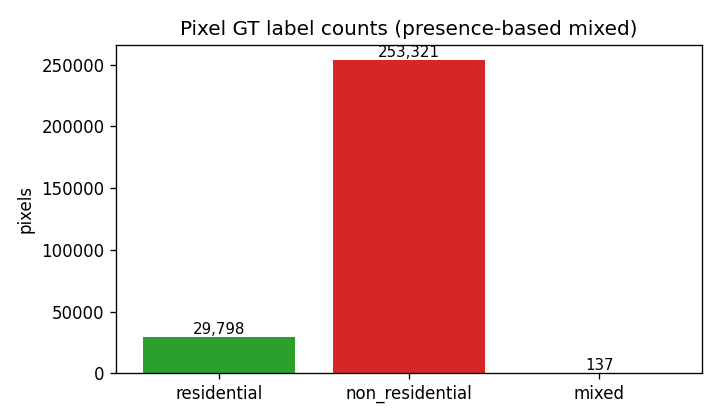

### `frac_histograms.png`

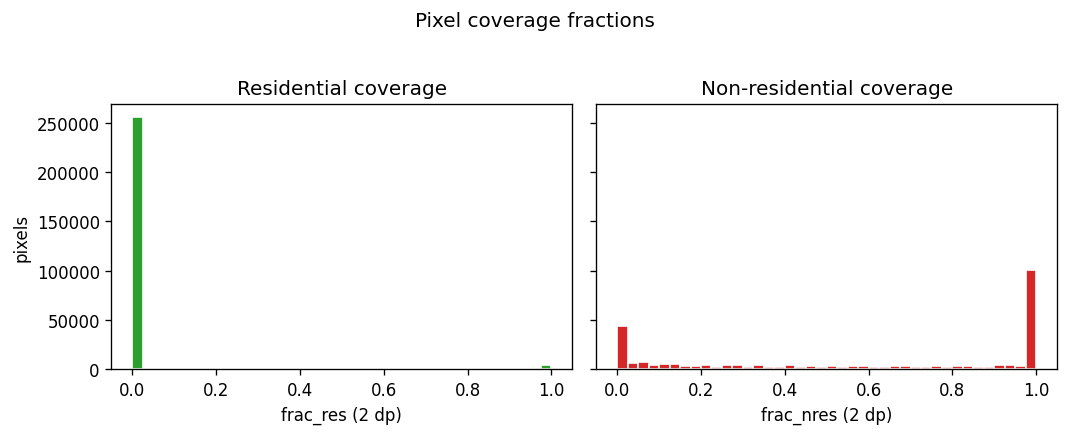

### `frac_scatter.png`

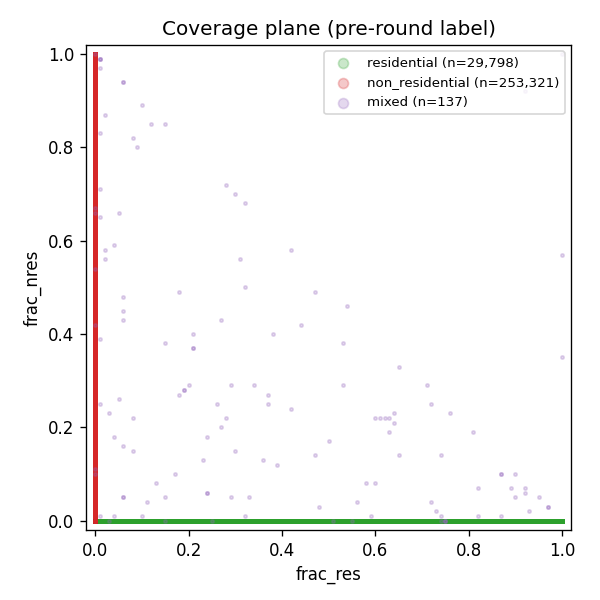

### `label_by_region.png`

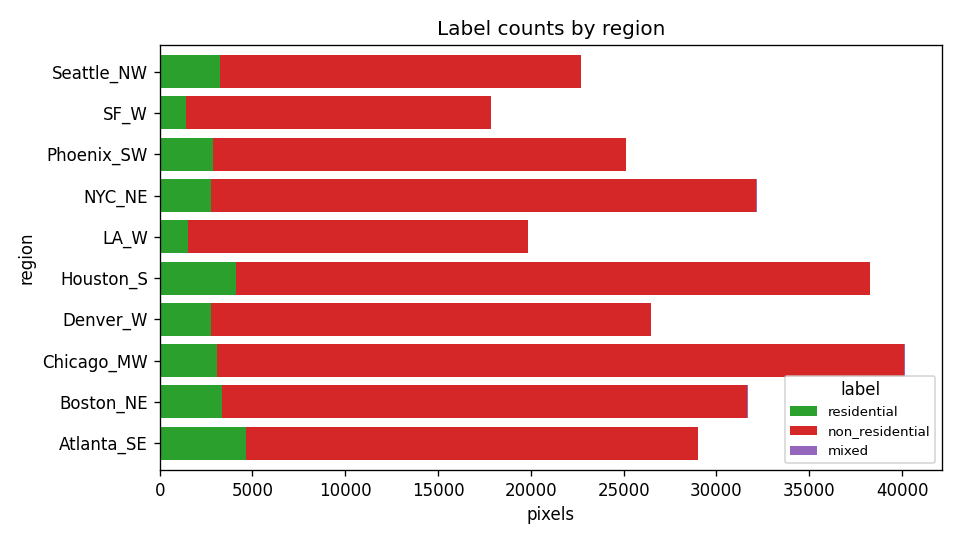

label,residential,non_residential,mixed,total,mixed_rate
region,,,,,
Chicago_MW,3068,37057,18,40143,0.0004
Houston_S,4132,34127,9,38268,0.0002
NYC_NE,2767,29342,55,32164,0.0017
Boston_NE,3344,28326,12,31682,0.0004
Atlanta_SE,4670,24315,13,28998,0.0004
Denver_W,2751,23720,12,26483,0.0005
Phoenix_SW,2863,22236,4,25103,0.0002
Seattle_NW,3248,19438,1,22687,0.0000
LA_W,1544,18315,6,19865,0.0003


n_res_buildings: {'count': 283256.0, 'mean': 0.10859787612618974, 'std': 0.3209644867195171, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 0.0, 'max': 4.0}
n_nres_buildings: {'count': 283256.0, 'mean': 0.9087715705933855, 'std': 0.33386663980134784, 'min': 0.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 4.0}
pixels with ≥2 buildings: 4784


In [4]:
for name in [
    "label_counts.png",
    "frac_histograms.png",
    "frac_scatter.png",
    "label_by_region.png",
]:
    path = FIG / name
    if not path.exists():
        import build_week3_pixel_gt as pix
        pix.write_qa_plots(df, FIG)
    display(Markdown(f"### `{name}`"))
    display(Image(filename=str(path)))

by_region = (
    df.groupby(["region", "label"]).size().unstack(fill_value=0)
    .reindex(columns=["residential", "non_residential", "mixed"], fill_value=0)
)
by_region["total"] = by_region.sum(axis=1)
by_region["mixed_rate"] = by_region["mixed"] / by_region["total"]
display(by_region.sort_values("total", ascending=False))

# Sanity: buildings per pixel
print("n_res_buildings:", df["n_res_buildings"].describe().to_dict())
print("n_nres_buildings:", df["n_nres_buildings"].describe().to_dict())
print(
    "pixels with ≥2 buildings:",
    int(((df["n_res_buildings"] + df["n_nres_buildings"]) >= 2).sum()),
)


## 4. Manifest snapshot


In [5]:
display(Markdown("```json\n" + json.dumps(manifest, indent=2)[:2500] + "\n...\n```"))
print("paths:")
for k, v in manifest.get("paths", {}).items():
    print(f"  {k}: {v}")


```json
{
  "name": "week3_pixel_gt_v1",
  "purpose": "Pixel-level RES/NRES/mixed GT at 10 m AlphaEarth cells from Overture Track-A footprints (presence-based mixed, not \u03c4=0.7 f_res).",
  "label_definition": "resi_def_v1_pixel_overlap_v1",
  "label_definition_doc": "docs/residential_definition_v1.md",
  "label_rule": {
    "residential": "overlaps RES GT only (frac_res>0, frac_nres==0) pre-round",
    "non_residential": "overlaps NRES GT only",
    "mixed": "overlaps both RES and NRES GT",
    "note": "Hard label uses pre-round overlap; frac_* written at 2 decimals."
  },
  "y_res_rule": "resi_def_v1 Building GT: 1 iff label in {single_family, multi_family}",
  "geometry_method": "per unique pixel: unary_union(RES footprints) \u2229 pixel / pixel.area (and same for NRES); STRtree over all region GT buildings",
  "sources": {
    "buildings": "datasets/building_bbox_grid/buildings.parquet",
    "cells": "datasets/building_bbox_grid/building_cells.parquet"
  },
  "n_pixels": 283256,
  "n_regions": 10,
  "regions": [
    "Atlanta_SE",
    "Boston_NE",
    "Chicago_MW",
    "Denver_W",
    "Houston_S",
    "LA_W",
    "NYC_NE",
    "Phoenix_SW",
    "SF_W",
    "Seattle_NW"
  ],
  "label_counts": {
    "non_residential": 253321,
    "residential": 29798,
    "mixed": 137
  },
  "label_counts_by_region": {
    "mixed": {
      "Atlanta_SE": 13,
      "Boston_NE": 12,
      "Chicago_MW": 18,
      "Denver_W": 12,
      "Houston_S": 9,
      "LA_W": 6,
      "NYC_NE": 55,
      "Phoenix_SW": 4,
      "SF_W": 7,
      "Seattle_NW": 1
    },
    "non_residential": {
      "Atlanta_SE": 24315,
      "Boston_NE": 28326,
      "Chicago_MW": 37057,
      "Denver_W": 23720,
      "Houston_S": 34127,
      "LA_W": 18315,
      "NYC_NE": 29342,
      "Phoenix_SW": 22236,
      "SF_W": 16445,
      "Seattle_NW": 19438
    },
    "residential": {
      "Atlanta_SE": 4670,
      "Boston_NE": 3344,
      "Chicago_MW": 3068,
      "Denver_W": 2751,
      "Houston_S": 4132,
      "LA_W": 1544,
      "NYC_NE": 2767,
      "Phoenix_SW": 2863,
      "SF_W": 1411,
      "Seattle_NW": 3248
    }
  },
  "frac_res": {
    "mean": 0.04690809726890163,
    "median": 0.0
  },
  "frac_nres": {
    "mean": 0.5810423433219418,
    "median": 0.67
  },
  "mixed_rate": 0.00048366142288248085,
  "embedding": {
    "bands": [
      "A00",
      "A01",
      "A02",
      "A03",
      "A04",
      "A05",
      "A06",
      "A07",
      "A08",
      "A09",
      "A10",
      "A11",
      "A12",
      
...
```

paths:
  pixels: datasets/week3_pixel_gt/pixels.parquet
  manifest: datasets/week3_pixel_gt/manifest.json
  figures: datasets/week3_pixel_gt/figures


## 5. Why are labels so imbalanced?

Not a bug in the pixel builder — two stacked effects from Track A:

1. **Building sampling is already NRES-heavy** (~2.7∶1 NRES∶RES buildings).
2. **NRES footprints are much larger**, so they dominate 10 m cells
   (median ~1.5k m² NRES vs ~280 m² RES → ~93% of footprint area / inside cells).

The pixel table is roughly **area-weighted over the Track A mix**, not
building-count-weighted. Single-family homes barely appear (median 1 inside
cell). Mixed is rare because RES and NRES rarely share the same 10 m cell.

For a balanced trainer later: subsample NRES pixels, class-weight, or upsample
RES — do not change the GT rule.


=== Building counts (Track A) ===


,n
class_res,
NRES,8191
RES,3089


ratio NRES/RES buildings: 2.65

=== Building footprint area (area_m2_approx) ===


,count,median,mean,sum
class_res,,,,
NRES,8191,1550.8799,3325.5672,27239721.1336
RES,3089,277.0590,706.1455,2181283.4327


area share NRES: 0.926

=== Cells per building ===
n_cells


...

  share NRES: 0.925

=== By study label (median footprint + inside cells) ===


,n,y_res,med_area,mean_area,med_cells_in,sum_cells_in,sum_area
label,,,,,,,
industrial,1287,0,1576.2085,5426.2958,9.0000,41839,6983642.6878
education,1840,0,2086.6155,3335.1374,13.0000,37373,6136652.8157
medical,594,0,3040.4278,5727.6146,18.0000,20635,3402203.0743
retail,1616,0,796.5004,1971.7920,5.0000,19085,3186415.9305
office,756,0,2302.1416,3218.5066,14.5000,14698,2433191.0082
civic,757,0,1392.9553,3088.1771,8.0000,14177,2337750.0842
multi_family,1102,1,703.6694,1487.4882,4.0000,10034,1639211.9838
hotel,539,0,1796.0301,2735.6508,10.0000,9053,1474515.7740
religious,802,0,1193.7077,1602.6805,7.0000,7923,1285349.7589



=== Pixel labels ===


,n
label,
non_residential,253321
residential,29798
mixed,137


ratio NRES/RES pixels: 8.50
nres share of covered area: 0.925


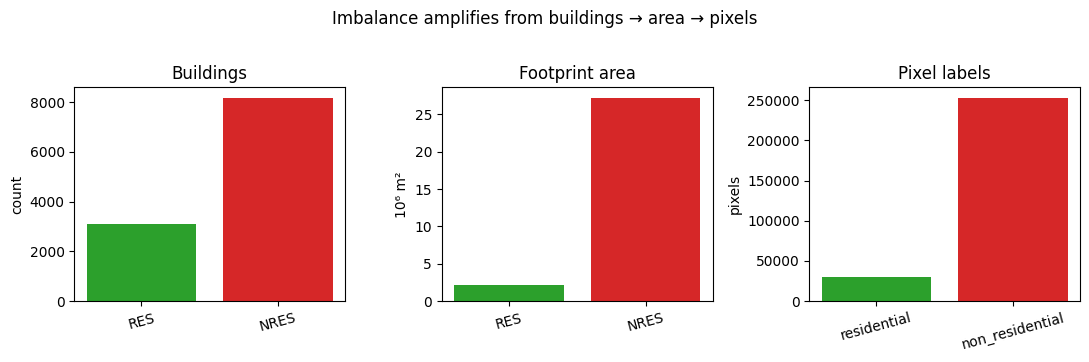

Saved `/data/users/kv133/Alpha-Earth-Embeddings-Research/datasets/week3_pixel_gt/figures/imbalance_stack.png`

In [6]:
b = pd.read_parquet(ROOT / "datasets/building_bbox_grid/buildings.parquet")
b = b.loc[b["y_res"].isin([0, 1])].copy()
b["class_res"] = np.where(b["y_res"] == 1, "RES", "NRES")

print("=== Building counts (Track A) ===")
bc = b["class_res"].value_counts()
display(bc.to_frame("n"))
print(f"ratio NRES/RES buildings: {bc['NRES'] / bc['RES']:.2f}")

print("\n=== Building footprint area (area_m2_approx) ===")
area = b.groupby("class_res")["area_m2_approx"].agg(["count", "median", "mean", "sum"])
display(area)
print(f"area share NRES: {area.loc['NRES', 'sum'] / area['sum'].sum():.3f}")

print("\n=== Cells per building ===")
for col in ["n_cells", "n_cells_inside_polygon"]:
    g = b.groupby("class_res")[col].agg(["median", "mean", "sum"])
    print(col)
    display(g)
    print(f"  share NRES: {g.loc['NRES', 'sum'] / g['sum'].sum():.3f}")

print("\n=== By study label (median footprint + inside cells) ===")
by_label = (
    b.groupby("label")
    .agg(
        n=("id", "size"),
        y_res=("y_res", "first"),
        med_area=("area_m2_approx", "median"),
        mean_area=("area_m2_approx", "mean"),
        med_cells_in=("n_cells_inside_polygon", "median"),
        sum_cells_in=("n_cells_inside_polygon", "sum"),
        sum_area=("area_m2_approx", "sum"),
    )
    .sort_values("sum_cells_in", ascending=False)
)
display(by_label)

print("\n=== Pixel labels ===")
pc = df["label"].value_counts()
display(pc.to_frame("n"))
print(
    f"ratio NRES/RES pixels: "
    f"{pc['non_residential'] / pc['residential']:.2f}"
)
print(
    f"nres share of covered area: "
    f"{df['area_nres_m2'].sum() / (df['area_res_m2'].sum() + df['area_nres_m2'].sum()):.3f}"
)

# Figure: building count vs pixel count vs footprint area
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
colors = {"RES": "#2ca02c", "NRES": "#d62728"}

axes[0].bar(["RES", "NRES"], [bc["RES"], bc["NRES"]], color=[colors["RES"], colors["NRES"]])
axes[0].set_title("Buildings")
axes[0].set_ylabel("count")

axes[1].bar(
    ["RES", "NRES"],
    [area.loc["RES", "sum"] / 1e6, area.loc["NRES", "sum"] / 1e6],
    color=[colors["RES"], colors["NRES"]],
)
axes[1].set_title("Footprint area")
axes[1].set_ylabel("10⁶ m²")

axes[2].bar(
    ["residential", "non_residential"],
    [pc["residential"], pc["non_residential"]],
    color=[colors["RES"], colors["NRES"]],
)
axes[2].set_title("Pixel labels")
axes[2].set_ylabel("pixels")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Imbalance amplifies from buildings → area → pixels", y=1.02)
fig.tight_layout()
fig.savefig(FIG / "imbalance_stack.png", dpi=120, bbox_inches="tight")
plt.show()
display(Markdown(f"Saved `{FIG / 'imbalance_stack.png'}`"))


## Notes / later stages (out of scope here)

- Trainer / LORO on these pixel rows
- Dense AOI inference beyond GT-covered pixels
- GHSL `pixel_eval` wiring
- Track B τ = 0.7 hard labels from \(f_{\mathrm{res}}\) — different rule; do not mix metrics
